# Step 7 — Next-day branch transaction models

Compare seasonal naive (lag 7), Random Forest and XGBoost. Use only a small predefined search and May to choose configurations. June is scored only after writing the validation selection lock. **Qualification:** June has already appeared in earlier EDA and other project tasks, so this is an internal chronological holdout, not a pristine external test. No preprocessing or hyperparameters are fit on June.

Forecast origin is after yesterday closes. June lag values use actual preceding June days as they become available; parameters stay fixed throughout the month. This is not a month-ahead forecast.

In [1]:
from pathlib import Path
import sys, os, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT/'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'src'))
from train_daily_models import split_data, tune, final_evaluation, write_report, FEATURES, GRID
DATA = Path(os.environ.get('STORIES_FEATURES', str(ROOT/'daily_demand_features.csv')))
feature_hash_before = hashlib.sha256(DATA.read_bytes()).hexdigest()
OUT = ROOT/'reports/demand_forecasting'
ARTIFACTS = ROOT/'artifacts/daily_demand_models'
train, validation, test = split_data(DATA)
display(pd.DataFrame([{'split':n,'start':str(d.Date.min().date()),'end':str(d.Date.max().date()),'rows':len(d)} for n,d in [('train',train),('validation',validation),('test',test)]]))
print('Predictors:', FEATURES)
assert 'Transactions' not in FEATURES and 'MissingBranchDay' not in FEATURES

Predictors: ['Branch', 'DayOfWeek', 'Month', 'DayOfMonth', 'Weekend', 'Lag1', 'Lag7', 'RollingMean7']


,split,start,end,rows
0,train,2026-01-08,2026-04-30,339
1,validation,2026-05-01,2026-05-31,93
2,test,2026-06-01,2026-06-30,90


## 1. Fix the small search before evaluating

Four Random Forest candidates: 300 trees, maximum depth 4/unlimited, minimum leaf 2/5. Four XGBoost candidates: depth 2/3 × 150/300 trees, learning rate .03, minimum child weight 5, L2 penalty 10, no subsampling. Fixed random seed 490. Only pooled May MAE selects the configuration and overall method.

Branch and weekday are one-hot encoded within each pipeline. Numeric features pass through unchanged. The encoder and estimator fit on Jan 8–Apr 30 only for validation. No scaling or imputation is needed. Missing required post-warmup history triggers an error rather than silently changing the evaluation sample.

In [2]:
display(pd.DataFrame([{'model':name, 'trial':i, **params} for name,grid in GRID.items() for i,params in enumerate(grid)]))
print('Number of ML configurations:', sum(len(g) for g in GRID.values()))

Number of ML configurations: 8


,model,trial,n_estimators,max_depth,min_samples_leaf,max_features,learning_rate,min_child_weight,reg_lambda,subsample,colsample_bytree
0,Random Forest,0,300,4.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN
1,Random Forest,1,300,4.0,5.0,1.0,NaN,NaN,NaN,NaN,NaN
2,Random Forest,2,300,NaN,2.0,1.0,NaN,NaN,NaN,NaN,NaN
3,Random Forest,3,300,NaN,5.0,1.0,NaN,NaN,NaN,NaN,NaN
4,XGBoost,0,150,2.0,NaN,NaN,0.03,5.0,10.0,1.0,1.0
5,XGBoost,1,300,2.0,NaN,NaN,0.03,5.0,10.0,1.0,1.0
6,XGBoost,2,150,3.0,NaN,NaN,0.03,5.0,10.0,1.0,1.0
7,XGBoost,3,300,3.0,NaN,NaN,0.03,5.0,10.0,1.0,1.0


## 2. Fit on January–April and select using May only

Seasonal naive copies lag 7 and fits no parameters. Each ML family picks its lowest-May-MAE configuration. The overall winner, including the baseline, is locked before any June model score is calculated. The complete search specification is written before fitting.

In [3]:
lock, validation_predictions = tune(train, validation, OUT)
display(pd.DataFrame(lock['validationMetrics']).T)
print('Selected on validation:', lock['selectedByMay'])
print('Selected settings:', json.dumps(lock['selectedSettings'], indent=2))
assert (OUT/'selection_lock.json').exists()

Selected on validation: XGBoost
Selected settings: {
  "Random Forest": {
    "trial": 0,
    "params": {
      "n_estimators": 300,
      "max_depth": 4,
      "min_samples_leaf": 2,
      "max_features": 1.0
    }
  },
  "XGBoost": {
    "trial": 1,
    "params": {
      "n_estimators": 300,
      "max_depth": 2,
      "learning_rate": 0.03,
      "min_child_weight": 5,
      "reg_lambda": 10,
      "subsample": 1.0,
      "colsample_bytree": 1.0
    }
  }
}


,MAE,RMSE,WAPE
Seasonal naive,8.935484,12.331880,0.129057
Random Forest,9.198721,13.151364,0.132859
XGBoost,8.252264,12.433786,0.119189


## 3. Final June evaluation

Keep the settings fixed. Refit each chosen ML pipeline on January 8–May 31, including its preprocessing, then predict June one day at a time using recorded prior-day features. No parameter updates during June. Report all three approaches; do not switch the saved choice after reading June.

MAE and RMSE are transactions per branch-day. WAPE is sum absolute error divided by total actual transactions, displayed as a fraction in raw tables (multiply by 100 for percent). It is not classification accuracy.

In [4]:
results = final_evaluation(train, validation, test, lock, validation_predictions, OUT, ARTIFACTS)
results['featureCSV_SHA256'] = feature_hash_before
(OUT/'model_results.json').write_text(json.dumps(results, indent=2))
write_report(results, OUT)
display(pd.DataFrame(results['test']).T)
print('Winner chosen on May:', results['selectedByValidation'])
print('Lowest June MAE (descriptive only):', results['lowestJuneMAE'])
print('June MAE reduction versus naive:', results['JuneMAEReductionVsNaive'])
print('Paired-date uncertainty:', results['selectedVsNaivePairedDayBootstrap'])

Winner chosen on May: XGBoost
Lowest June MAE (descriptive only): XGBoost
June MAE reduction versus naive: {'Seasonal naive': 0.0, 'Random Forest': -0.04708992876121698, 'XGBoost': 0.05192358184743806}
Paired-date uncertainty: {'replicates': 1000, 'metric': 'Naive MAE minus validation-selected model MAE; positive favors selected', 'ci95': [-0.72941108862559, 1.8134203820758394], 'limitation': '30 June dates; assumes date clusters sufficiently independent. Cross-day serial dependence may remain.'}


,MAE,RMSE,WAPE
Seasonal naive,9.600000,11.611297,0.125109
Random Forest,10.052063,13.493361,0.131000
XGBoost,9.101534,12.278624,0.118613


## 4. Branch-level validation and test results

A pooled average can hide a weak branch. All three branches are shown, using the same global configurations. No separate branch hyperparameter selection is performed.

,split,branch,model,MAE,RMSE,WAPE
3,validation,Harbour,Seasonal naive,12.258065,16.875254,0.122186
4,validation,Harbour,Random Forest,12.290046,17.654754,0.122505
5,validation,Harbour,XGBoost,12.158639,17.826978,0.121195
6,validation,Garden,Seasonal naive,7.290323,9.193265,0.106203
7,validation,Garden,Random Forest,9.182405,11.645327,0.133766
8,validation,Garden,XGBoost,6.550729,8.737525,0.095429
9,validation,Uptown,Seasonal naive,7.258065,9.323920,0.187344
10,validation,Uptown,Random Forest,6.123711,8.459972,0.158064
11,validation,Uptown,XGBoost,6.047425,8.345754,0.156095
15,test,Harbour,Seasonal naive,11.233333,13.826303,0.099527


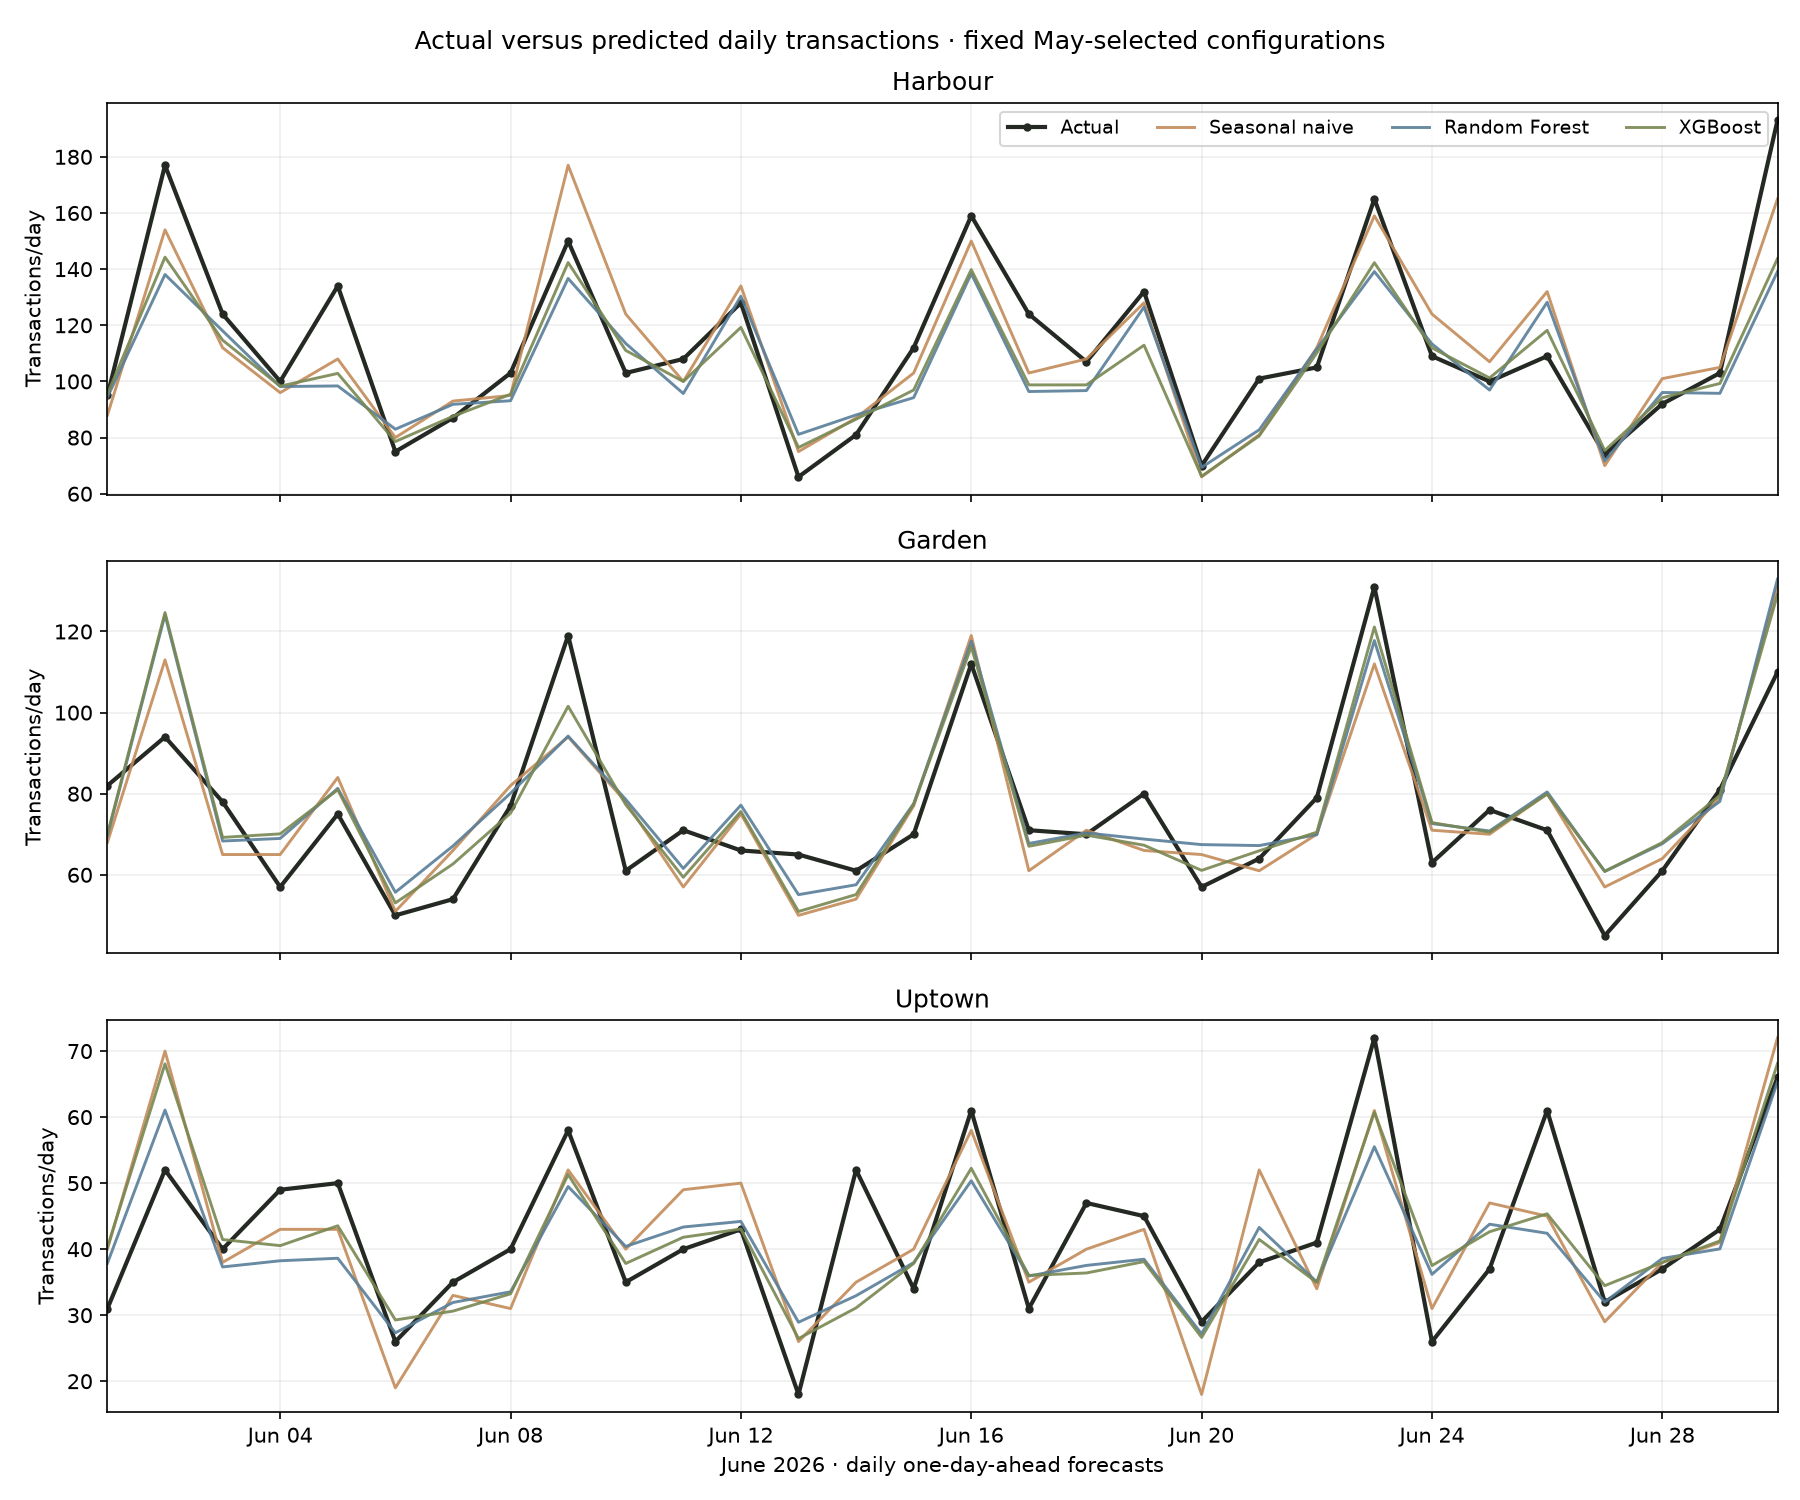

In [5]:
comparison = pd.read_csv(OUT/'model_comparison.csv')
display(comparison[comparison.branch!='ALL'])
display(Image(filename=str(ROOT/'figures/demand_forecasting/june_actual_vs_predicted.png')))

## 5. Save, reload and interpret

`best_model.joblib` stores the May-selected pipeline (or a declared Lag7 rule if the baseline wins), its predictor schema and fit dates. Both selected ML pipelines and validation/June row-level predictions remain in ignored `artifacts/daily_demand_models/`. Aggregate metrics, the search, the lock and manifest are in `reports/demand_forecasting/`.

Lower transaction error may support better planning, but no dollar gain, reduction in waste, causal promotion response or crisis accuracy is measured here. Transaction counts alone cannot determine SKU preparation quantities. Later financial scenarios must include margins, product mix, unsold inventory, capacity and intervention costs.

In [6]:
import joblib
from train_daily_models import metric
bundle = joblib.load(ARTIFACTS/'best_model.joblib')
if bundle['model'] is None:
    reloaded_predictions = test['Lag7'].to_numpy(float)
else:
    reloaded_predictions = np.maximum(bundle['model'].predict(test[FEATURES]), 0)
reloaded_scores = metric(test.Transactions, reloaded_predictions)
for key,value in reloaded_scores.items():
    assert np.isclose(value, results['test'][bundle['manifest']['selectedByValidation']][key])
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == feature_hash_before
display(pd.DataFrame({'validation':pd.DataFrame(results['validation']).T.MAE,'June_test':pd.DataFrame(results['test']).T.MAE}).rename_axis('model'))
print('PASS: saved winner reproduces scores; feature CSV unchanged.')

PASS: saved winner reproduces scores; feature CSV unchanged.


,validation,June_test
model,,
Seasonal naive,8.935484,9.600000
Random Forest,9.198721,10.052063
XGBoost,8.252264,9.101534


## 6. Business interpretation and mixed evidence

The goal is a defensible one-day-ahead transaction forecast, not a high classification accuracy score. Lower MAE does not guarantee fewer large errors, better results at every branch, or additional profit. Keep the overall model choice fixed by May and treat June branch winners as descriptive. Transaction forecasting alone cannot specify product preparation or disruption response.

In [7]:
from pathlib import Path
import json
r = json.loads((ROOT/'reports/demand_forecasting/model_results.json').read_text())
chosen = r['selectedByValidation']
print('Model selected on May:', chosen)
print('June MAE reduction vs naive:', f"{r['JuneMAEReductionVsNaive'][chosen]:.2%}")
print('June RMSE winner:', min(r['test'], key=lambda name:r['test'][name]['RMSE']))
print('June branch MAE winners (descriptive, not a new selection):', {b:min(scores,key=lambda name:scores[name]['MAE']) for b,scores in r['perBranch']['test'].items()})
ci = r['selectedVsNaivePairedDayBootstrap']['ci95']
print('Date-bootstrap improvement interval:', ci)
print('Interval includes zero:', ci[0] <= 0 <= ci[1])
print('No measured revenue gain or disruption-specific accuracy is established by these results.')

Model selected on May: XGBoost
June MAE reduction vs naive: 5.19%
June RMSE winner: Seasonal naive
June branch MAE winners (descriptive, not a new selection): {'Harbour': 'Seasonal naive', 'Garden': 'XGBoost', 'Uptown': 'XGBoost'}
Date-bootstrap improvement interval: [-0.72941108862559, 1.8134203820758394]
Interval includes zero: True
No measured revenue gain or disruption-specific accuracy is established by these results.
